# OLIST-2 · Preparar o dataset e calcular os indicadores básicos

**Tech Challenge Agentic AI — Fase 1 (FIAP)** · Responsável: Igor · Grupo: Diogo, Igor e Lorran

**O que o enunciado pede:** usar o dataset público da Olist e suas 8 tabelas (Enunciado, p. 3–4) para fazer análises que mostrem os problemas e oportunidades do negócio. Essa parte é avaliada no critério 3, *capacidade analítica* (Enunciado, p. 5).

**Objetivo deste notebook:** conhecer as tabelas e o que cada linha representa e definir as regras que tornam os números corretos. Com elas, calcular os indicadores básicos que os outros cards vão usar (OLIST-3 achados, OLIST-5 matriz, OLIST-6 KPIs).

| Etapa | O que sai dela | Critério de aceite |
|---|---|---|
| Dicionário | o que é cada tabela, suas colunas e para que serve | CA1 |
| 0. Preparação | bibliotecas e estilo dos gráficos | — |
| 1. Carga e inventário | registros, colunas e chave de cada tabela | CA1 |
| 2. Granularidade e chaves | o que é "1 linha" em cada tabela e como elas se ligam | CA1 |
| 3. Nulos | onde faltam dados e por quê | CA2 |
| 4. Período e status | datas cobertas e situação dos pedidos | CA5 |
| 5. Regras de qualidade | 8 regras em linguagem simples, cada uma checada | CA2 |
| 6. Base de pedidos | 1 linha por pedido, com as regras aplicadas | CA3 |
| 7. Indicadores | 15 indicadores, cada um com definição, fórmula e tabela de origem | CA3, CA5 |
| 8. Exportação | Excel com fórmulas vivas, JSON e figuras | CA3, CA4 |
| 9. Checklist | critérios de aceite do card | todos |

**Como rodar:** abra a pasta do projeto no VS Code ou Jupyter, selecione o ambiente `.venv` e execute *Run All*. Os CSVs precisam estar em `data/raw/` (veja `data/raw/README.md`).

## Dicionário do dataset
Antes de abrir os dados, vale saber o que cada tabela guarda e para que ela serve na análise. O dataset é o *Brazilian E-Commerce Public Dataset by Olist* (Kaggle). Ele tem 8 tabelas citadas no enunciado (p. 3–4) e mais uma de apoio. A Olist anonimizou todos os identificadores (`*_id`): eles servem para ligar as tabelas, não para identificar pessoas.

### Visão geral

| Tabela (arquivo) | O que é | 1 linha representa | Liga com | Para que serve na análise |
|---|---|---|---|---|
| **orders** (`olist_orders_dataset.csv`) | O pedido e as datas do seu ciclo, da compra à entrega | um pedido | customers, order_items, payments, order_reviews | Centro do modelo: volume, status, prazo de entrega e atraso |
| **customers** (`olist_customers_dataset.csv`) | O cliente de cada pedido e onde ele mora | um cliente em um pedido | orders, geolocation | Contar clientes reais, medir recompra e fazer recortes por estado e cidade |
| **order_items** (`olist_order_items_dataset.csv`) | Os itens comprados em cada pedido, com preço e frete | um item dentro de um pedido | orders, products, sellers | Valor vendido, frete, produtos e vendedores envolvidos em cada pedido |
| **payments** (`olist_order_payments_dataset.csv`) | Como cada pedido foi pago | uma forma de pagamento usada no pedido | orders | Valor pago, meio de pagamento e parcelamento |
| **order_reviews** (`olist_order_reviews_dataset.csv`) | A avaliação do cliente depois da compra | uma avaliação ligada a um pedido | orders | Satisfação (nota), comentários em texto e tempo de resposta da pesquisa |
| **products** (`olist_products_dataset.csv`) | O cadastro dos produtos vendidos | um produto | order_items, category_translation | Recortes por categoria, peso e tamanho (que pesam no frete) |
| **sellers** (`olist_sellers_dataset.csv`) | O cadastro dos vendedores (lojistas) parceiros | um vendedor | order_items, geolocation | Concentração de vendas e de atrasos por vendedor e por estado de origem |
| **geolocation** (`olist_geolocation_dataset.csv`) | Coordenadas de cada prefixo de CEP | um ponto de coordenada (o CEP se repete) | customers, sellers (por CEP) | Mapas e distância entre vendedor e cliente |
| *category_translation* (`product_category_name_translation.csv`) | Tradução das categorias para o inglês (apoio) | uma categoria | products | Padronizar os nomes das categorias em gráficos e relatórios |

### Colunas de cada tabela

**orders**: o pedido

| Coluna | Descrição |
|---|---|
| `order_id` | Identificador único do pedido (chave da tabela) |
| `customer_id` | Cliente do pedido; liga com `customers`. Cada pedido gera um `customer_id` novo |
| `order_status` | Situação do pedido: `delivered`, `shipped`, `canceled`, `unavailable`, `invoiced`, `processing`, `created`, `approved` |
| `order_purchase_timestamp` | Data e hora da compra |
| `order_approved_at` | Data e hora em que o pagamento foi aprovado |
| `order_delivered_carrier_date` | Data em que o vendedor entregou o pedido à transportadora (postagem) |
| `order_delivered_customer_date` | Data em que o cliente recebeu o pedido |
| `order_estimated_delivery_date` | Data de entrega prometida ao cliente na compra (sem hora) |

**customers**: o cliente

| Coluna | Descrição |
|---|---|
| `customer_id` | Identificador do cliente **naquele pedido** (chave da tabela; liga com `orders`) |
| `customer_unique_id` | Identificador da **pessoa**: é o mesmo em todas as compras do cliente. Use para contar clientes e recompra |
| `customer_zip_code_prefix` | 5 primeiros dígitos do CEP do cliente; liga com `geolocation` |
| `customer_city` | Cidade do cliente |
| `customer_state` | Estado (UF) do cliente |

**order_items**: os itens do pedido

| Coluna | Descrição |
|---|---|
| `order_id` | Pedido ao qual o item pertence; liga com `orders` |
| `order_item_id` | Número sequencial do item dentro do pedido (1, 2, 3…). Junto com `order_id`, forma a chave |
| `product_id` | Produto vendido; liga com `products` |
| `seller_id` | Vendedor do item; liga com `sellers` |
| `shipping_limit_date` | Prazo para o vendedor postar o item na transportadora |
| `price` | Preço do item (R$) |
| `freight_value` | Frete do item (R$). Se o pedido tem vários itens, o frete é dividido entre eles |

**payments**: o pagamento

| Coluna | Descrição |
|---|---|
| `order_id` | Pedido pago; liga com `orders` |
| `payment_sequential` | Número da forma de pagamento no pedido. Quem paga com mais de um meio, como cartão e voucher, gera várias linhas |
| `payment_type` | Meio de pagamento: `credit_card`, `boleto`, `voucher`, `debit_card`, `not_defined` |
| `payment_installments` | Número de parcelas |
| `payment_value` | Valor pago naquela forma de pagamento (R$) |

**order_reviews**: a avaliação

| Coluna | Descrição |
|---|---|
| `review_id` | Identificador da avaliação. Pode se repetir em pedidos diferentes |
| `order_id` | Pedido avaliado; liga com `orders` |
| `review_score` | Nota de 1 (pior) a 5 (melhor) |
| `review_comment_title` | Título do comentário, em português. Opcional, quase sempre vazio |
| `review_comment_message` | Texto do comentário, em português. Opcional; é o material para agentes que leem avaliações |
| `review_creation_date` | Data em que a pesquisa de satisfação foi enviada ao cliente |
| `review_answer_timestamp` | Data e hora em que o cliente respondeu |

**products**: o produto

| Coluna | Descrição |
|---|---|
| `product_id` | Identificador único do produto (chave da tabela) |
| `product_category_name` | Categoria em português; liga com `category_translation` |
| `product_name_lenght` | Quantidade de caracteres do nome do produto. O nome da coluna tem um erro de digitação no original (*lenght*) |
| `product_description_lenght` | Quantidade de caracteres da descrição do produto |
| `product_photos_qty` | Quantidade de fotos publicadas no anúncio |
| `product_weight_g` | Peso (gramas) |
| `product_length_cm` | Comprimento (cm) |
| `product_height_cm` | Altura (cm) |
| `product_width_cm` | Largura (cm) |

**sellers**: o vendedor

| Coluna | Descrição |
|---|---|
| `seller_id` | Identificador único do vendedor (chave da tabela) |
| `seller_zip_code_prefix` | 5 primeiros dígitos do CEP do vendedor; liga com `geolocation` |
| `seller_city` | Cidade do vendedor |
| `seller_state` | Estado (UF) do vendedor |

**geolocation**: a localização dos CEPs

| Coluna | Descrição |
|---|---|
| `geolocation_zip_code_prefix` | 5 primeiros dígitos do CEP. **Não é único**: o mesmo CEP tem vários pontos |
| `geolocation_lat` | Latitude |
| `geolocation_lng` | Longitude |
| `geolocation_city` | Cidade |
| `geolocation_state` | Estado (UF) |

**category_translation**: tradução das categorias, tabela de apoio

| Coluna | Descrição |
|---|---|
| `product_category_name` | Categoria em português (como em `products`) |
| `product_category_name_english` | Mesma categoria em inglês |

> As Etapas 1 e 2 conferem este dicionário nos dados: quantas linhas cada tabela tem, se a chave é mesmo única e se as ligações encontram par do outro lado.

## Etapa 0 · Preparação
Carregamos as bibliotecas e o pacote do projeto (`src/olist`). O pacote só guarda o que é repetitivo: caminhos, leitura dos CSVs, estilo dos gráficos e exportação. Toda a análise fica aqui no notebook, à vista.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from matplotlib.ticker import FuncFormatter, MultipleLocator, PercentFormatter

from olist import config, io, viz
from olist.viz import fmt_int, fmt_pct
from olist.quality import RuleBook
from olist.indicators import IndicatorBook
from olist.export import to_excel, to_json

viz.setup()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
print("Pasta do projeto:", ROOT)

Pasta do projeto: C:\Users\igor_\OneDrive\Área de Trabalho\Case FIAP


## Etapa 1 · Carga e inventário das tabelas
**Pergunta:** quantos registros cada tabela tem, qual é a chave dela e o que cada linha representa?

A função `io.load_table` lê cada CSV sem alterar nenhum valor. Ela só converte as datas para o tipo data e lê os CEPs como texto, para não perder os zeros à esquerda.

In [2]:
t = io.load_all()

linhas = []
for nome, df in t.items():
    spec = config.TABLES[nome]
    key = spec["key"]
    linhas.append({
        "tabela": nome,
        "no_enunciado": "sim" if nome in config.ENUNCIADO_TABLES else "apoio",
        "registros": len(df),
        "colunas": df.shape[1],
        "chave": " + ".join(key),
        "chave_e_unica": "sim" if not df.duplicated(key).any() else "não",
        "granularidade": spec["grain"],
        "pct_celulas_vazias": round(df.isna().mean().mean(), 4),
        "memoria_MB": round(df.memory_usage(deep=True).sum() / 1e6, 1),
    })
inventario = pd.DataFrame(linhas).sort_values("registros", ascending=False, ignore_index=True)
inventario

,tabela,no_enunciado,registros,colunas,chave,chave_e_unica,granularidade,pct_celulas_vazias,memoria_MB
0,geolocation,sim,1000163,5,geolocation_zip_code_prefix,não,1 linha por ponto de coordenada (o mesmo CEP a...,0.00,181.70
1,order_items,sim,112650,7,order_id + order_item_id,sim,1 linha por item dentro do pedido,0.00,31.00
2,payments,sim,103886,5,order_id + payment_sequential,sim,1 linha por forma de pagamento usada no pedido,0.00,17.00
3,customers,sim,99441,5,customer_id,sim,1 linha por cliente-em-um-pedido (o mesmo clie...,0.00,32.50
4,orders,sim,99441,8,order_id,sim,1 linha por pedido,0.01,25.90
5,order_reviews,sim,99224,7,review_id + order_id,sim,1 linha por avaliação ligada a um pedido (há p...,0.21,29.10
6,products,sim,32951,9,product_id,sim,1 linha por produto,0.01,6.60
7,sellers,sim,3095,4,seller_id,sim,1 linha por vendedor,0.00,0.80
8,category_translation,apoio,71,2,product_category_name,sim,1 linha por categoria (tradução para inglês),0.00,0.00


**Como ler:** `chave_e_unica = não` quer dizer que a coluna que parece ser a chave se repete. Isso acontece na `geolocation`: o mesmo prefixo de CEP aparece em várias linhas, uma por coordenada. Ela não pode ser cruzada direto com outras tabelas (regra R7).

O gráfico abaixo usa escala logarítmica. Sem ela, a `geolocation`, com cerca de 1 milhão de linhas, esconderia todas as outras tabelas.

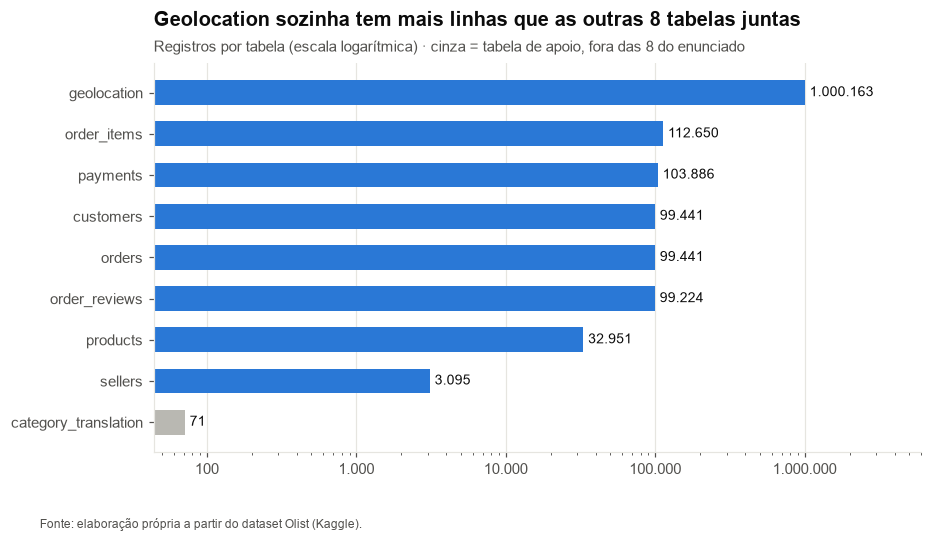

In [3]:
inv = inventario.sort_values("registros")
fig, ax = plt.subplots(figsize=(9, 4.6))
cores = [viz.SERIES[0] if s == "sim" else viz.MUTED for s in inv["no_enunciado"]]
ax.barh(inv["tabela"], inv["registros"], color=cores, height=0.6)
ax.set_xscale("log")
ax.grid(axis="y", visible=False)
for y, v in enumerate(inv["registros"]):
    ax.text(v * 1.08, y, fmt_int(v), va="center", fontsize=9, color=viz.TEXT)
ax.set_xlim(right=inv["registros"].max() * 6)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: fmt_int(v)))
viz.titles(ax, "Geolocation sozinha tem mais linhas que as outras 8 tabelas juntas",
           "Registros por tabela (escala logarítmica) · cinza = tabela de apoio, fora das 8 do enunciado")
viz.save(fig, "g01_registros_por_tabela")
plt.show()

## Etapa 2 · Granularidade e chaves
**Granularidade** é o que uma linha representa: um pedido, um item do pedido, um pagamento… Erros de contagem acontecem quando se mistura granularidades. Por exemplo, contar pedidos na tabela de itens conta o mesmo pedido mais de uma vez.

O gráfico mostra **quantas linhas existem para cada "coisa" que a tabela descreve**:
- 1,0 = uma linha por pedido, produto etc.;
- acima de 1 = a "coisa" se repete. Antes de cruzar a tabela com outra, é preciso **agregar**, ou seja, resumir para 1 linha.

In [4]:
entidade = {  # tabela -> (coluna da "coisa" descrita, nome amigável)
    "orders": ("order_id", "pedido"),
    "order_items": ("order_id", "pedido"),
    "payments": ("order_id", "pedido"),
    "order_reviews": ("order_id", "pedido"),
    "customers": ("customer_unique_id", "cliente real"),
    "products": ("product_id", "produto"),
    "sellers": ("seller_id", "vendedor"),
    "geolocation": ("geolocation_zip_code_prefix", "prefixo de CEP"),
    "category_translation": ("product_category_name", "categoria"),
}
gran = pd.DataFrame([
    {"tabela": tb, "entidade": nome, "linhas": len(t[tb]), "entidades_distintas": t[tb][col].nunique()}
    for tb, (col, nome) in entidade.items()
])
gran["linhas_por_entidade"] = gran["linhas"] / gran["entidades_distintas"]
gran = gran.sort_values("linhas_por_entidade", ignore_index=True)
gran

,tabela,entidade,linhas,entidades_distintas,linhas_por_entidade
0,orders,pedido,99441,99441,1.00
1,products,produto,32951,32951,1.00
2,sellers,vendedor,3095,3095,1.00
3,category_translation,categoria,71,71,1.00
4,order_reviews,pedido,99224,98673,1.01
5,customers,cliente real,99441,96096,1.03
6,payments,pedido,103886,99440,1.04
7,order_items,pedido,112650,98666,1.14
8,geolocation,prefixo de CEP,1000163,19015,52.60


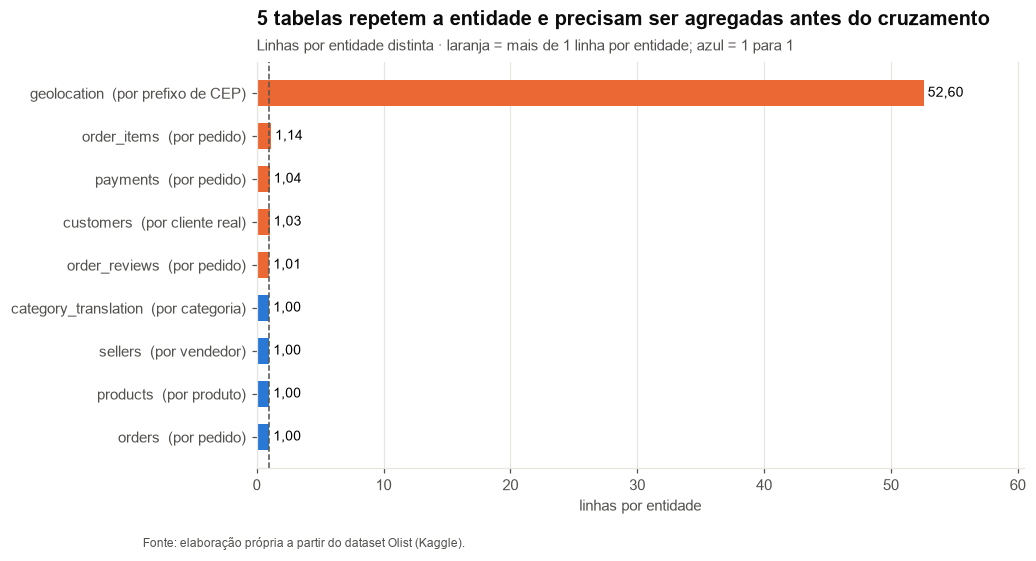

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.8))
cores = [viz.SERIES[1] if v > 1.005 else viz.SERIES[0] for v in gran["linhas_por_entidade"]]
rotulos = [f"{tb}  (por {ent})" for tb, ent in zip(gran["tabela"], gran["entidade"])]
ax.barh(rotulos, gran["linhas_por_entidade"], color=cores, height=0.6)
ax.axvline(1, color=viz.TEXT_2, lw=1, ls="--")
ax.grid(axis="y", visible=False)
for y, v in enumerate(gran["linhas_por_entidade"]):
    ax.text(v + 0.3, y, f"{v:.2f}".replace(".", ","), va="center", fontsize=9)
ax.set_xlim(0, gran["linhas_por_entidade"].max() * 1.15)
ax.set_xlabel("linhas por entidade")
n_rep = int((gran["linhas_por_entidade"] > 1.005).sum())
viz.titles(ax, f"{n_rep} tabelas repetem a entidade e precisam ser agregadas antes do cruzamento",
           "Linhas por entidade distinta · laranja = mais de 1 linha por entidade; azul = 1 para 1")
viz.save(fig, "g02_linhas_por_entidade")
plt.show()

### Mapa das chaves
Diagrama de relacionamento: **PK** é a chave da tabela e **FK** é a coluna que aponta para outra tabela. **N:1** quer dizer "muitas linhas aqui para uma linha lá". Tudo gira em torno do **pedido** (`order_id`).

A geolocalização se liga por **prefixo de CEP**, que não é único. Por isso a ligação aparece tracejada.

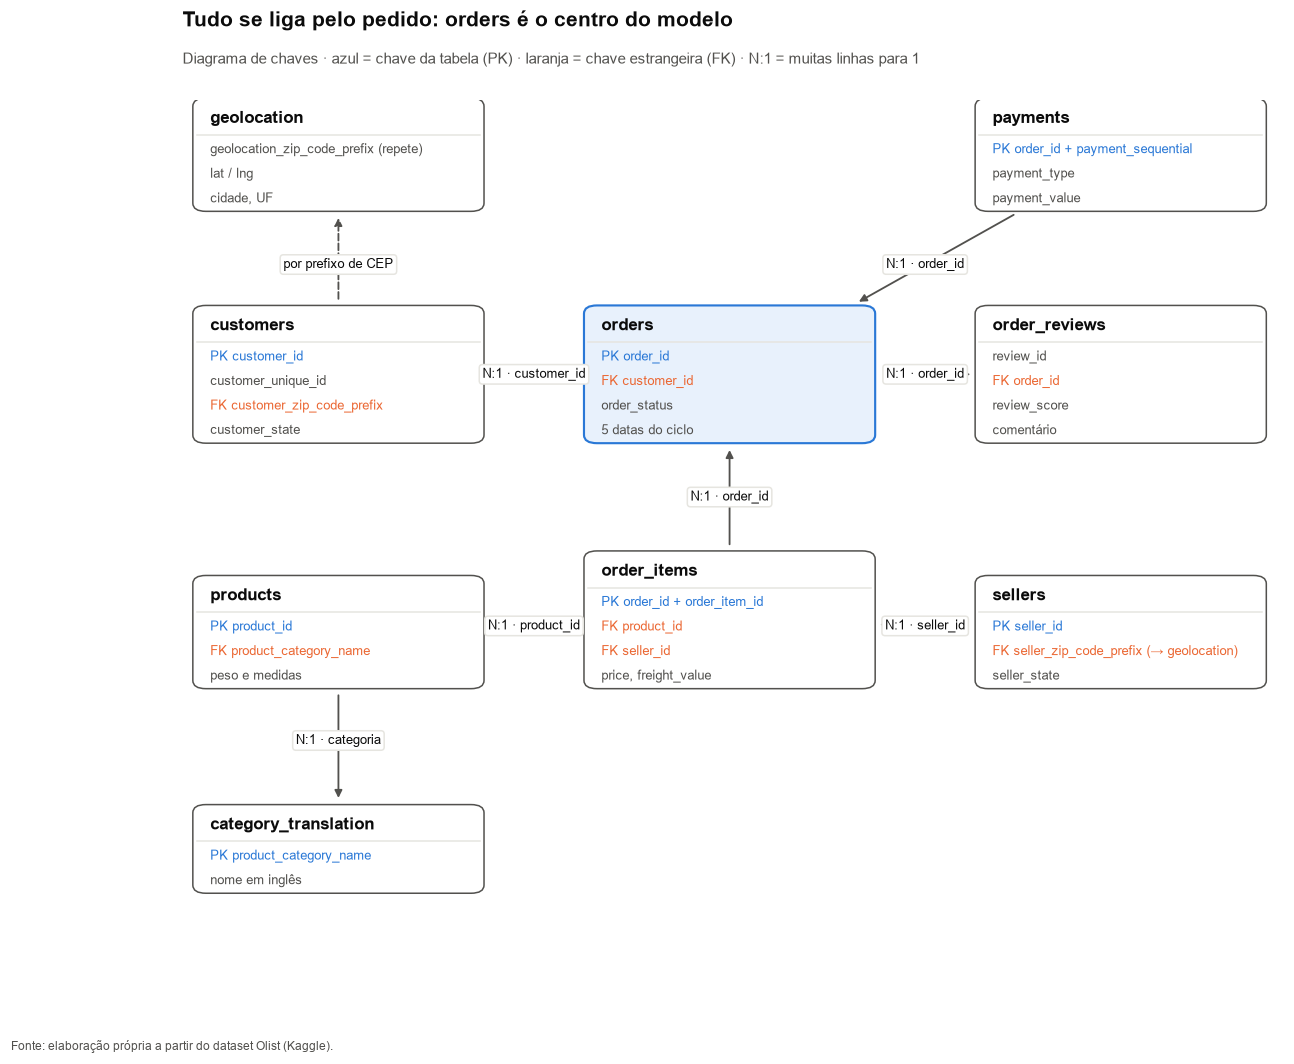

In [6]:
boxes = {  # nome: (x, y, campos) — coordenadas de um canvas 0–100
    "geolocation": (1, 74, ["geolocation_zip_code_prefix (repete)", "lat / lng", "cidade, UF"]),
    "customers": (1, 40, ["PK customer_id", "customer_unique_id", "FK customer_zip_code_prefix", "customer_state"]),
    "orders": (37, 40, ["PK order_id", "FK customer_id", "order_status", "5 datas do ciclo"]),
    "payments": (73, 74, ["PK order_id + payment_sequential", "payment_type", "payment_value"]),
    "order_reviews": (73, 40, ["review_id", "FK order_id", "review_score", "comentário"]),
    "order_items": (37, 4, ["PK order_id + order_item_id", "FK product_id", "FK seller_id", "price, freight_value"]),
    "products": (1, 4, ["PK product_id", "FK product_category_name", "peso e medidas"]),
    "sellers": (73, 4, ["PK seller_id", "FK seller_zip_code_prefix (→ geolocation)", "seller_state"]),
    "category_translation": (1, -26, ["PK product_category_name", "nome em inglês"]),
}
W, LINE, HEAD = 26, 3.6, 5.0
fig, ax = plt.subplots(figsize=(13, 9.5))
ax.set_xlim(-1, 101); ax.set_ylim(-28, 90); ax.axis("off")
patches = {}
for nome, (x, y, campos) in boxes.items():
    h = HEAD + LINE * len(campos)
    destaque = nome == "orders"
    p = FancyBboxPatch((x, y), W, h, boxstyle="round,pad=0.4,rounding_size=1.2",
                       fc="#e8f1fc" if destaque else viz.SURFACE, ec=viz.SERIES[0] if destaque else viz.TEXT_2, lw=1.4 if destaque else 1)
    ax.add_patch(p); patches[nome] = p
    ax.text(x + 1.2, y + h - 2.6, nome, fontsize=11, fontweight="bold", color=viz.TEXT, va="center")
    ax.plot([x, x + W], [y + h - HEAD, y + h - HEAD], color=viz.GRID, lw=1)
    for i, campo in enumerate(campos):
        cor = viz.SERIES[0] if campo.startswith("PK") else (viz.SERIES[1] if campo.startswith("FK") else viz.TEXT_2)
        ax.text(x + 1.2, y + h - HEAD - LINE * (i + 0.6), campo, fontsize=8.6, color=cor, va="center")

def liga(filho, pai, rotulo, tracejado=False, curva=0.0):
    a, b = patches[filho], patches[pai]
    ca = (a.get_x() + a.get_width() / 2, a.get_y() + a.get_height() / 2)
    cb = (b.get_x() + b.get_width() / 2, b.get_y() + b.get_height() / 2)
    arrow = ax.annotate("", xy=cb, xytext=ca, arrowprops=dict(
        arrowstyle="-|>", color=viz.TEXT_2, lw=1.2, ls="--" if tracejado else "-",
        patchA=a, patchB=b, shrinkA=4, shrinkB=4, connectionstyle=f"arc3,rad={curva}"))
    mx, my = (ca[0] + cb[0]) / 2, (ca[1] + cb[1]) / 2
    ax.text(mx, my + curva * 18, rotulo, fontsize=8.5, color=viz.TEXT, ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.25", fc=viz.SURFACE, ec=viz.GRID))

liga("orders", "customers", "N:1 · customer_id")
liga("order_items", "orders", "N:1 · order_id")
liga("payments", "orders", "N:1 · order_id")
liga("order_reviews", "orders", "N:1 · order_id")
liga("order_items", "products", "N:1 · product_id")
liga("order_items", "sellers", "N:1 · seller_id")
liga("products", "category_translation", "N:1 · categoria")
liga("customers", "geolocation", "por prefixo de CEP", tracejado=True)
fig.text(0.13, 0.95, "Tudo se liga pelo pedido: orders é o centro do modelo", fontsize=14, fontweight="bold", color=viz.TEXT)
fig.text(0.13, 0.925, "Diagrama de chaves · azul = chave da tabela (PK) · laranja = chave estrangeira (FK) · N:1 = muitas linhas para 1",
        color=viz.TEXT_2, fontsize=10, va="top")
viz.save(fig, "g03_mapa_de_chaves")
plt.show()

### Integridade referencial
**Pergunta:** quando uma tabela aponta para outra, o valor existe do outro lado?

Exemplo: todo `product_id` dos itens existe em `products`? Abaixo de 100% significa que, no cruzamento, alguns registros ficam sem par. Isso não é erro nosso, mas precisa ser declarado.

In [7]:
integ = []
for filho, col, pai, col_pai in config.RELATIONS:
    valores = t[filho][col].dropna()
    achados = valores.isin(set(t[pai][col_pai].dropna()))
    integ.append({"ligacao": f"{filho}.{col} → {pai}", "valores": len(valores), "encontrados": int(achados.sum()),
                  "pct_encontrado": achados.mean()})
pedidos_ids = t["orders"]["order_id"]
for tb, nome in [("order_items", "pedidos com item"), ("payments", "pedidos com pagamento"), ("order_reviews", "pedidos com avaliação")]:
    tem = pedidos_ids.isin(set(t[tb]["order_id"]))
    integ.append({"ligacao": f"orders → {tb} ({nome})", "valores": len(pedidos_ids), "encontrados": int(tem.sum()), "pct_encontrado": tem.mean()})
integ = pd.DataFrame(integ).sort_values("pct_encontrado", ignore_index=True)
integ

,ligacao,valores,encontrados,pct_encontrado
0,orders → order_items (pedidos com item),99441,98666,0.99
1,orders → order_reviews (pedidos com avaliação),99441,98673,0.99
2,customers.customer_zip_code_prefix → geolocation,99441,99163,1.00
3,sellers.seller_zip_code_prefix → geolocation,3095,3088,1.00
4,products.product_category_name → category_tran...,32341,32328,1.00
5,orders → payments (pedidos com pagamento),99441,99440,1.00
6,orders.customer_id → customers,99441,99441,1.00
7,order_items.order_id → orders,112650,112650,1.00
8,payments.order_id → orders,103886,103886,1.00
9,order_reviews.order_id → orders,99224,99224,1.00


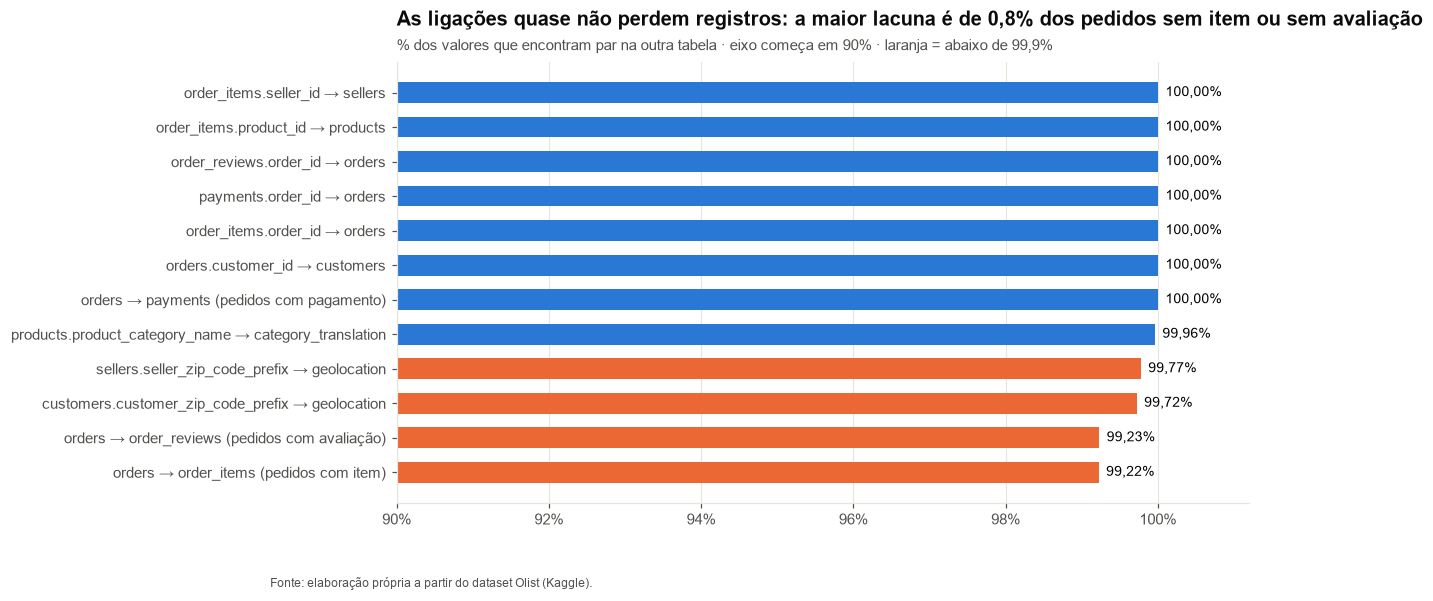

In [8]:
fig, ax = plt.subplots(figsize=(10, 5.2))
cores = [viz.SERIES[1] if v < 0.999 else viz.SERIES[0] for v in integ["pct_encontrado"]]
ax.barh(integ["ligacao"], integ["pct_encontrado"], color=cores, height=0.6)
ax.set_xlim(0.9, 1.012)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.grid(axis="y", visible=False)
for y, v in enumerate(integ["pct_encontrado"]):
    ax.text(min(v, 1.0) + 0.001, y, fmt_pct(v, 2), va="center", fontsize=9)
viz.titles(ax, f"As ligações quase não perdem registros: a maior lacuna é de {fmt_pct(1 - integ['pct_encontrado'].min())} dos pedidos sem item ou sem avaliação",
           "% dos valores que encontram par na outra tabela · eixo começa em 90% · laranja = abaixo de 99,9%")
viz.save(fig, "g04_integridade_referencial")
plt.show()

## Etapa 3 · Onde faltam dados (nulos)
**Pergunta:** quais colunas têm valores vazios? O vazio é um problema ou faz parte do processo?

Muitos vazios são **esperados**:
- um pedido cancelado não tem data de entrega;
- o cliente não é obrigado a escrever comentário.

A regra (R5) é **não trocar vazio por zero**. Um comentário ausente não é uma nota zero, e um pedido sem data de entrega não teve prazo zero.

In [9]:
nulos = []
for nome, df in t.items():
    for col, pct in df.isna().mean().items():
        if pct > 0:
            nulos.append({"coluna": f"{nome}.{col}", "pct_vazio": pct, "vazios": int(df[col].isna().sum())})
nulos = pd.DataFrame(nulos).sort_values("pct_vazio", ignore_index=True)
nulos

,coluna,pct_vazio,vazios
0,products.product_width_cm,0.00,2
1,products.product_height_cm,0.00,2
2,products.product_length_cm,0.00,2
3,products.product_weight_g,0.00,2
4,orders.order_approved_at,0.00,160
5,orders.order_delivered_carrier_date,0.02,1783
6,products.product_name_lenght,0.02,610
7,products.product_category_name,0.02,610
8,products.product_photos_qty,0.02,610
9,products.product_description_lenght,0.02,610


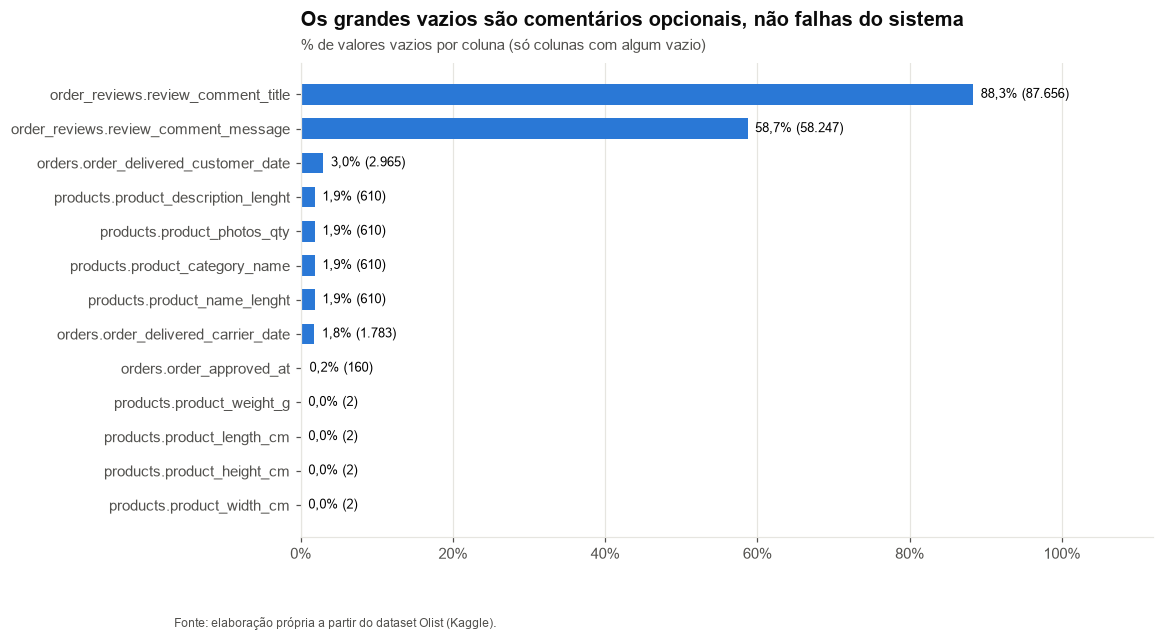

In [10]:
fig, ax = plt.subplots(figsize=(10, 5.6))
ax.barh(nulos["coluna"], nulos["pct_vazio"], color=viz.SERIES[0], height=0.6)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.grid(axis="y", visible=False)
for y, (v, n) in enumerate(zip(nulos["pct_vazio"], nulos["vazios"])):
    ax.text(v + 0.01, y, f"{fmt_pct(v)} ({fmt_int(n)})", va="center", fontsize=8.5)
ax.set_xlim(0, 1.12)
viz.titles(ax, "Os grandes vazios são comentários opcionais, não falhas do sistema",
           "% de valores vazios por coluna (só colunas com algum vazio)")
viz.save(fig, "g05_nulos_por_coluna")
plt.show()

**Leitura dos vazios:**

| Coluna | Por que fica vazia | Tratamento |
|---|---|---|
| `review_comment_title` / `review_comment_message` | comentário é opcional | vira o indicador "% com comentário"; nunca vira texto vazio contado como comentário |
| datas de entrega (`order_delivered_*`) | pedido não entregue (cancelado, em trânsito, indisponível) | só pedidos entregues entram no prazo e no atraso (R4) |
| `order_approved_at` | pedido não aprovado (cancelado antes) | não usado nos indicadores-base |
| `product_category_name` e medidas do produto | cadastro incompleto do produto | produto fica como "sem categoria" em análises por categoria (OLIST-3) |

## Etapa 4 · Período e status dos pedidos
**Pergunta:** que datas o dataset cobre e em que situação estão os pedidos?

Meses com poucos pedidos no começo e no fim são **meses de borda**: a coleta começou ou terminou no meio deles. Comparar esses meses com os outros distorce tendências, então eles aparecem em cinza.

Primeira compra: 04/09/2016 · última: 17/10/2018
Meses de borda (menos de 10% da mediana mensal = 428 pedidos): ['2016-09', '2016-10', '2016-12', '2018-09', '2018-10']


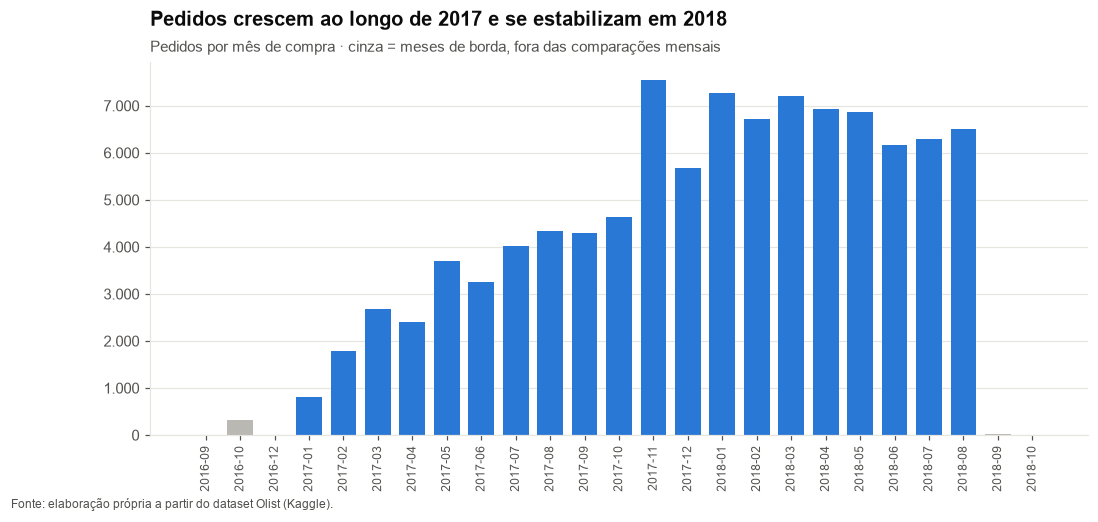

In [11]:
orders = t["orders"]
mes = orders["order_purchase_timestamp"].dt.to_period("M")
por_mes = mes.value_counts().sort_index()
limite_borda = por_mes.median() * 0.10
borda = por_mes[por_mes < limite_borda].index.astype(str).tolist()
print(f"Primeira compra: {orders['order_purchase_timestamp'].min():%d/%m/%Y} · última: {orders['order_purchase_timestamp'].max():%d/%m/%Y}")
print(f"Meses de borda (menos de 10% da mediana mensal = {limite_borda:.0f} pedidos):", borda)

fig, ax = plt.subplots(figsize=(11, 4.4))
cores = [viz.MUTED if str(p) in borda else viz.SERIES[0] for p in por_mes.index]
ax.bar(por_mes.index.astype(str), por_mes.values, color=cores, width=0.75)
ax.grid(axis="x", visible=False)
ax.tick_params(axis="x", rotation=90, labelsize=8)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: fmt_int(v)))
viz.titles(ax, "Pedidos crescem ao longo de 2017 e se estabilizam em 2018",
           "Pedidos por mês de compra · cinza = meses de borda, fora das comparações mensais")
viz.save(fig, "g06_pedidos_por_mes")
plt.show()

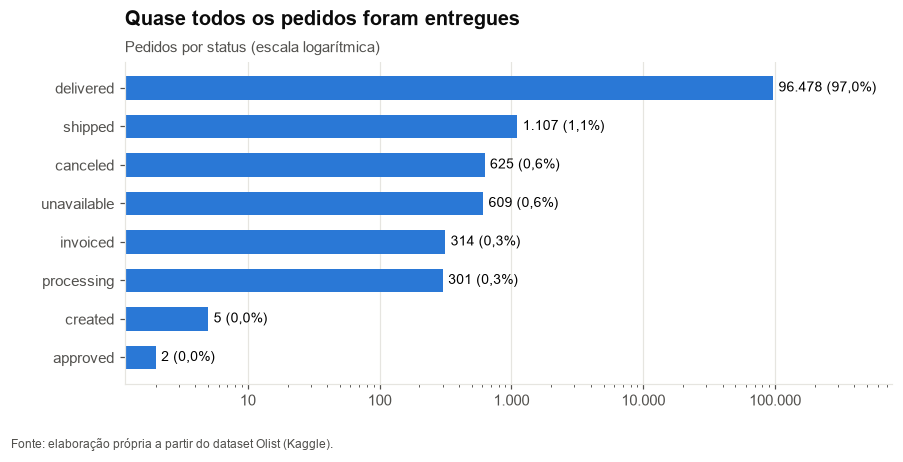

In [12]:
status = orders["order_status"].value_counts()
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(status.index[::-1], status.values[::-1], color=viz.SERIES[0], height=0.6)
ax.set_xscale("log")
ax.grid(axis="y", visible=False)
for y, v in enumerate(status.values[::-1]):
    ax.text(v * 1.1, y, f"{fmt_int(v)} ({fmt_pct(v / status.sum())})", va="center", fontsize=9)
ax.set_xlim(right=status.max() * 8)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: fmt_int(v)))
viz.titles(ax, "Quase todos os pedidos foram entregues",
           "Pedidos por status (escala logarítmica)")
viz.save(fig, "g07_pedidos_por_status")
plt.show()

## Etapa 5 · Regras de qualidade
Cada regra responde a uma **armadilha real** do dataset. Por que 8? O card pede no mínimo 6. Esse número é meta do grupo, não do PDF. Seis armadilhas mudam diretamente os indicadores básicos (R1 a R6) e duas protegem cruzamentos futuros (R7 e R8).

Para cada regra, a célula mede quantos registros ela afeta e faz uma checagem que imprime **OK** ou **ALERTA**.

In [13]:
rules = RuleBook()
items, payments, reviews, customers = t["order_items"], t["payments"], t["order_reviews"], t["customers"]
products, geo = t["products"], t["geolocation"]

**R1 · Pedido se conta pelo `order_id` da tabela `orders`.** A tabela de itens tem uma linha por item e a de pagamentos uma linha por forma de pagamento. Contar linhas nelas conta o mesmo pedido várias vezes.

In [14]:
pedidos_com_item = items["order_id"].nunique()
rules.add(
    id="R1", regra="Pedido se conta pelo order_id da tabela orders, nunca pelas linhas de itens ou pagamentos.",
    motivo=f"Contar linhas de order_items infla o número de pedidos em {fmt_pct(len(items) / pedidos_com_item - 1)}.",
    afetados=len(items) - pedidos_com_item, base=f"{fmt_int(len(items))} linhas de itens",
    ok=not orders["order_id"].duplicated().any(),
    evidencia=f"orders: {fmt_int(len(orders))} linhas e nenhum order_id repetido; "
              f"order_items: {fmt_int(len(items))} linhas para {fmt_int(pedidos_com_item)} pedidos.",
)

[OK] R1 · Pedido se conta pelo order_id da tabela orders, nunca pelas linhas de itens ou pagamentos.
        orders: 99.441 linhas e nenhum order_id repetido; order_items: 112.650 linhas para 98.666 pedidos.


Rule(id='R1', regra='Pedido se conta pelo order_id da tabela orders, nunca pelas linhas de itens ou pagamentos.', motivo='Contar linhas de order_items infla o número de pedidos em 14,2%.', afetados=13984, base='112.650 linhas de itens', ok=True, evidencia='orders: 99.441 linhas e nenhum order_id repetido; order_items: 112.650 linhas para 98.666 pedidos.')

**R2 · Cliente se conta pelo `customer_unique_id`.** O `customer_id` muda a cada pedido. Contar por ele faz cada pedido parecer um cliente novo, e a recompra some.

In [15]:
n_cid, n_uid = customers["customer_id"].nunique(), customers["customer_unique_id"].nunique()
rules.add(
    id="R2", regra="Cliente se conta pelo customer_unique_id (a pessoa), não pelo customer_id (o cadastro de cada pedido).",
    motivo=f"Por customer_id seriam {fmt_int(n_cid)} clientes; na verdade são {fmt_int(n_uid)} pessoas.",
    afetados=n_cid - n_uid, base=f"{fmt_int(n_cid)} customer_id",
    ok=(orders["customer_id"].is_unique and customers["customer_id"].is_unique),
    evidencia=f"Cada customer_id aparece em exatamente 1 pedido; {fmt_int(n_cid - n_uid)} cadastros são de pessoas que já tinham comprado.",
)

[OK] R2 · Cliente se conta pelo customer_unique_id (a pessoa), não pelo customer_id (o cadastro de cada pedido).
        Cada customer_id aparece em exatamente 1 pedido; 3.345 cadastros são de pessoas que já tinham comprado.


Rule(id='R2', regra='Cliente se conta pelo customer_unique_id (a pessoa), não pelo customer_id (o cadastro de cada pedido).', motivo='Por customer_id seriam 99.441 clientes; na verdade são 96.096 pessoas.', afetados=3345, base='99.441 customer_id', ok=True, evidencia='Cada customer_id aparece em exatamente 1 pedido; 3.345 cadastros são de pessoas que já tinham comprado.')

**R3 · Uma avaliação por pedido: fica a mais recente.** Há pedidos com mais de uma avaliação e avaliações (`review_id`) ligadas a mais de um pedido. Cruzar sem agregar duplica pedidos e notas.

In [16]:
rev_por_pedido = reviews["order_id"].value_counts()
reviews_ped = (reviews.sort_values(["order_id", "review_answer_timestamp", "review_creation_date"])
                      .drop_duplicates("order_id", keep="last").copy())
msg = reviews_ped["review_comment_message"].astype("string").str.strip()
reviews_ped["tem_comentario"] = (msg.notna() & (msg != "")).astype(int)
rules.add(
    id="R3", regra="Cada pedido fica com uma única avaliação: a mais recente.",
    motivo=f"{fmt_int((rev_por_pedido > 1).sum())} pedidos têm mais de uma avaliação e "
           f"{fmt_int(reviews['review_id'].duplicated().sum())} review_id se repetem em pedidos diferentes.",
    afetados=len(reviews) - len(reviews_ped), base=f"{fmt_int(len(reviews))} avaliações",
    ok=reviews_ped["order_id"].is_unique,
    evidencia=f"{fmt_int(len(reviews))} avaliações viraram {fmt_int(len(reviews_ped))}, exatamente 1 por pedido avaliado.",
)

[OK] R3 · Cada pedido fica com uma única avaliação: a mais recente.
        99.224 avaliações viraram 98.673, exatamente 1 por pedido avaliado.


Rule(id='R3', regra='Cada pedido fica com uma única avaliação: a mais recente.', motivo='547 pedidos têm mais de uma avaliação e 814 review_id se repetem em pedidos diferentes.', afetados=551, base='99.224 avaliações', ok=True, evidencia='99.224 avaliações viraram 98.673, exatamente 1 por pedido avaliado.')

**R4 · Atraso só existe para pedido entregue, com as duas datas preenchidas.** Não faz sentido falar em atraso de pedido cancelado ou ainda em trânsito. Há também pedidos marcados como entregues sem data de entrega.

In [17]:
entregue = orders["order_status"].eq("delivered")
datas_ok = orders["order_delivered_customer_date"].notna() & orders["order_estimated_delivery_date"].notna()
entregue_sem_data = int((entregue & ~datas_ok).sum())
rules.add(
    id="R4", regra="Prazo e atraso só são calculados para pedidos com status delivered e com data de entrega e data prometida preenchidas.",
    motivo=f"{fmt_int((~entregue).sum())} pedidos não foram entregues e {entregue_sem_data} estão como entregues sem data de entrega.",
    afetados=int((~(entregue & datas_ok)).sum()), base=f"{fmt_int(len(orders))} pedidos",
    ok=True,
    evidencia=f"{fmt_int((entregue & datas_ok).sum())} pedidos entram no cálculo de prazo (antes da R6).",
)

[OK] R4 · Prazo e atraso só são calculados para pedidos com status delivered e com data de entrega e data prometida preenchidas.
        96.470 pedidos entram no cálculo de prazo (antes da R6).


Rule(id='R4', regra='Prazo e atraso só são calculados para pedidos com status delivered e com data de entrega e data prometida preenchidas.', motivo='2.963 pedidos não foram entregues e 8 estão como entregues sem data de entrega.', afetados=2971, base='99.441 pedidos', ok=True, evidencia='96.470 pedidos entram no cálculo de prazo (antes da R6).')

**R5 · Vazio não vira zero.** Um pedido sem avaliação não tem nota 0. Um produto sem peso não pesa 0 g. Trocar vazio por zero puxa médias para baixo e cria números que não existem.

In [18]:
pedidos_sem_review = int((~orders["order_id"].isin(reviews_ped["order_id"])).sum())
produtos_sem_medida = int(products[["product_weight_g", "product_length_cm"]].isna().any(axis=1).sum())
rules.add(
    id="R5", regra="Valor ausente continua ausente: nunca é trocado por zero nem por média; o indicador declara sobre quantos registros foi calculado.",
    motivo=f"{fmt_int(pedidos_sem_review)} pedidos não têm avaliação e {produtos_sem_medida} produtos não têm peso ou medida.",
    afetados=pedidos_sem_review + produtos_sem_medida, base="pedidos sem avaliação + produtos sem medida",
    ok=True,  # conferido de novo na base de pedidos (etapa 6)
    evidencia="Nenhum fillna é usado; a base de pedidos mantém células vazias onde não há dado.",
)

[OK] R5 · Valor ausente continua ausente: nunca é trocado por zero nem por média; o indicador declara sobre quantos registros foi calculado.
        Nenhum fillna é usado; a base de pedidos mantém células vazias onde não há dado.


Rule(id='R5', regra='Valor ausente continua ausente: nunca é trocado por zero nem por média; o indicador declara sobre quantos registros foi calculado.', motivo='768 pedidos não têm avaliação e 2 produtos não têm peso ou medida.', afetados=770, base='pedidos sem avaliação + produtos sem medida', ok=True, evidencia='Nenhum fillna é usado; a base de pedidos mantém células vazias onde não há dado.')

**R6 · Datas incoerentes ficam fora dos prazos.** Alguns pedidos têm entrega ao cliente **antes** da compra ou antes da postagem na transportadora. Isso é erro de registro e geraria prazos negativos.

In [19]:
compra = orders["order_purchase_timestamp"]
postagem = orders["order_delivered_carrier_date"]
entrega = orders["order_delivered_customer_date"]
incoerente = (entrega < compra) | (entrega < postagem)
rules.add(
    id="R6", regra="Pedido com data de entrega anterior à compra ou à postagem não entra nos cálculos de prazo e atraso.",
    motivo=f"{fmt_int(incoerente.sum())} pedidos têm a entrega registrada antes da compra ou da postagem.",
    afetados=int((incoerente & entregue & datas_ok).sum()), base=f"{fmt_int((entregue & datas_ok).sum())} pedidos entregues com datas",
    ok=True,
    evidencia=f"Também há {fmt_int((postagem < compra).sum())} postagens registradas antes da compra (apenas sinalizadas, pois não entram nos indicadores).",
)

[OK] R6 · Pedido com data de entrega anterior à compra ou à postagem não entra nos cálculos de prazo e atraso.
        Também há 166 postagens registradas antes da compra (apenas sinalizadas, pois não entram nos indicadores).


Rule(id='R6', regra='Pedido com data de entrega anterior à compra ou à postagem não entra nos cálculos de prazo e atraso.', motivo='23 pedidos têm a entrega registrada antes da compra ou da postagem.', afetados=23, base='96.470 pedidos entregues com datas', ok=True, evidencia='Também há 166 postagens registradas antes da compra (apenas sinalizadas, pois não entram nos indicadores).')

**R7 · Geolocalização: um ponto por prefixo de CEP.** A tabela tem cerca de 1 milhão de linhas, com o mesmo CEP repetido e algumas coordenadas fora do Brasil. Para cruzar com clientes ou vendedores, primeiro reduzimos a 1 linha por CEP, pela mediana das coordenadas válidas.

In [20]:
dentro_br = geo["geolocation_lat"].between(-34, 5.5) & geo["geolocation_lng"].between(-74, -34)
geo_cep = (geo[dentro_br].groupby("geolocation_zip_code_prefix")
              .agg(lat=("geolocation_lat", "median"), lng=("geolocation_lng", "median"),
                   uf=("geolocation_state", lambda s: s.mode().iat[0]))
              .reset_index())
cobertura = customers["customer_zip_code_prefix"].isin(set(geo_cep["geolocation_zip_code_prefix"])).mean()
rules.add(
    id="R7", regra="Antes de cruzar, a geolocalização é reduzida a 1 linha por prefixo de CEP (mediana das coordenadas dentro do Brasil).",
    motivo=f"{fmt_int(len(geo))} linhas para {fmt_int(geo['geolocation_zip_code_prefix'].nunique())} CEPs; {fmt_int((~dentro_br).sum())} coordenadas fora do Brasil.",
    afetados=len(geo) - len(geo_cep), base=f"{fmt_int(len(geo))} linhas de geolocalização",
    ok=geo_cep["geolocation_zip_code_prefix"].is_unique,
    evidencia=f"{fmt_int(len(geo_cep))} CEPs únicos; {fmt_pct(cobertura)} dos clientes encontram seu CEP.",
)

[OK] R7 · Antes de cruzar, a geolocalização é reduzida a 1 linha por prefixo de CEP (mediana das coordenadas dentro do Brasil).
        19.010 CEPs únicos; 99,7% dos clientes encontram seu CEP.


Rule(id='R7', regra='Antes de cruzar, a geolocalização é reduzida a 1 linha por prefixo de CEP (mediana das coordenadas dentro do Brasil).', motivo='1.000.163 linhas para 19.015 CEPs; 42 coordenadas fora do Brasil.', afetados=981153, base='1.000.163 linhas de geolocalização', ok=True, evidencia='19.010 CEPs únicos; 99,7% dos clientes encontram seu CEP.')

**R8 · Valor do pedido = soma dos pagamentos, conferida com itens + frete.** O que o cliente pagou está em `payments`. A soma de preço e frete dos itens deveria bater com esse valor. Quando não bate, a diferença costuma vir de juros de parcelamento ou de vouchers.

In [21]:
itens_ped = items.groupby("order_id").agg(n_itens=("order_item_id", "count"), valor_itens=("price", "sum"),
                                           valor_frete=("freight_value", "sum"))
pag_ped = payments.groupby("order_id").agg(valor_pago=("payment_value", "sum"))
conf = itens_ped.join(pag_ped, how="inner")
diferente = (conf["valor_pago"] - (conf["valor_itens"] + conf["valor_frete"])).abs() > 1.0
sem_pagamento = int((~orders["order_id"].isin(pag_ped.index)).sum())
rules.add(
    id="R8", regra="Valor do pedido é a soma dos pagamentos do pedido; a soma de preço + frete dos itens serve de conferência.",
    motivo=f"{fmt_int(diferente.sum())} pedidos ({fmt_pct(diferente.mean())}) têm diferença acima de R$ 1 entre pago e itens + frete.",
    afetados=int(diferente.sum()), base=f"{fmt_int(len(conf))} pedidos com itens e pagamento",
    ok=diferente.mean() < 0.05,
    evidencia=f"Diferenças ficam declaradas, não corrigidas; {sem_pagamento} pedido(s) sem registro de pagamento.",
)

[OK] R8 · Valor do pedido é a soma dos pagamentos do pedido; a soma de preço + frete dos itens serve de conferência.
        Diferenças ficam declaradas, não corrigidas; 1 pedido(s) sem registro de pagamento.


Rule(id='R8', regra='Valor do pedido é a soma dos pagamentos do pedido; a soma de preço + frete dos itens serve de conferência.', motivo='249 pedidos (0,3%) têm diferença acima de R$ 1 entre pago e itens + frete.', afetados=249, base='98.665 pedidos com itens e pagamento', ok=np.True_, evidencia='Diferenças ficam declaradas, não corrigidas; 1 pedido(s) sem registro de pagamento.')

In [22]:
regras = rules.to_frame()
regras

,id,regra,motivo,afetados,base,ok,evidencia
0,R1,Pedido se conta pelo order_id da tabela orders...,Contar linhas de order_items infla o número de...,13984,112.650 linhas de itens,True,orders: 99.441 linhas e nenhum order_id repeti...
1,R2,Cliente se conta pelo customer_unique_id (a pe...,Por customer_id seriam 99.441 clientes; na ver...,3345,99.441 customer_id,True,Cada customer_id aparece em exatamente 1 pedid...
2,R3,Cada pedido fica com uma única avaliação: a ma...,547 pedidos têm mais de uma avaliação e 814 re...,551,99.224 avaliações,True,"99.224 avaliações viraram 98.673, exatamente 1..."
3,R4,Prazo e atraso só são calculados para pedidos ...,2.963 pedidos não foram entregues e 8 estão co...,2971,99.441 pedidos,True,96.470 pedidos entram no cálculo de prazo (ant...
4,R5,Valor ausente continua ausente: nunca é trocad...,768 pedidos não têm avaliação e 2 produtos não...,770,pedidos sem avaliação + produtos sem medida,True,Nenhum fillna é usado; a base de pedidos manté...
5,R6,Pedido com data de entrega anterior à compra o...,23 pedidos têm a entrega registrada antes da c...,23,96.470 pedidos entregues com datas,True,Também há 166 postagens registradas antes da c...
6,R7,"Antes de cruzar, a geolocalização é reduzida a...",1.000.163 linhas para 19.015 CEPs; 42 coordena...,981153,1.000.163 linhas de geolocalização,True,"19.010 CEPs únicos; 99,7% dos clientes encontr..."
7,R8,Valor do pedido é a soma dos pagamentos do ped...,"249 pedidos (0,3%) têm diferença acima de R$ 1...",249,98.665 pedidos com itens e pagamento,True,"Diferenças ficam declaradas, não corrigidas; 1..."


## Etapa 6 · Base de pedidos (1 linha por pedido)
Juntamos tudo na granularidade do **pedido**, com as regras aplicadas. Essa base:
- alimenta todos os indicadores;
- vai para o Excel, onde cada indicador pode ser recalculado com fórmula;
- é salva em `data/processed/base_pedidos.csv` para os próximos cards.

Colunas de marcação (1 = sim, 0 = não, vazio = não se aplica): `entregue_valido`, `atrasado`, `cancelado_indisp` e `tem_comentario`.

In [23]:
valido = entregue & datas_ok & ~incoerente
prometida = orders["order_estimated_delivery_date"]

base = pd.DataFrame({
    "order_id": orders["order_id"],
    "customer_id": orders["customer_id"],
    "order_status": orders["order_status"],
    "data_compra": compra,
    "ano_mes": compra.dt.to_period("M").astype(str),
    "data_entrega": entrega,
    "data_prometida": prometida,
    "entregue_valido": valido.astype(int),
    "prazo_dias": ((entrega - compra).dt.total_seconds() / 86400).round(2).where(valido),
    "atraso_dias": (entrega.dt.normalize() - prometida.dt.normalize()).dt.days.where(valido),
    "cancelado_indisp": orders["order_status"].isin(["canceled", "unavailable"]).astype(int),
})
base["atrasado"] = (base["atraso_dias"] > 0).astype(float).where(valido)
base = (base.merge(customers[["customer_id", "customer_unique_id", "customer_state"]], on="customer_id", how="left")
            .merge(reviews_ped[["order_id", "review_score", "tem_comentario"]], on="order_id", how="left")
            .merge(itens_ped.reset_index(), on="order_id", how="left")
            .merge(pag_ped.reset_index(), on="order_id", how="left")
            .drop(columns="customer_id"))
base = base[["order_id", "customer_unique_id", "customer_state", "order_status", "data_compra", "ano_mes",
             "data_entrega", "data_prometida", "entregue_valido", "prazo_dias", "atraso_dias", "atrasado",
             "cancelado_indisp", "review_score", "tem_comentario", "n_itens", "valor_itens", "valor_frete", "valor_pago"]]

assert base["order_id"].is_unique and len(base) == len(orders)               # R1
assert base["review_score"].isna().sum() == pedidos_sem_review               # R5: vazio continua vazio
assert (base["prazo_dias"].dropna() >= 0).all()                               # R6
config.PROCESSED.mkdir(parents=True, exist_ok=True)
base.to_csv(config.PROCESSED / "base_pedidos.csv", index=False)
print(f"base_pedidos: {fmt_int(len(base))} linhas × {base.shape[1]} colunas · salva em data/processed/")
base.head()

base_pedidos: 99.441 linhas × 19 colunas · salva em data/processed/


,order_id,customer_unique_id,customer_state,order_status,data_compra,ano_mes,data_entrega,data_prometida,entregue_valido,prazo_dias,atraso_dias,atrasado,cancelado_indisp,review_score,tem_comentario,n_itens,valor_itens,valor_frete,valor_pago
0,e481f51cbdc54678b7cc49136f2d6af7,7c396fd4830fd04220f754e42b4e5bff,SP,delivered,2017-10-02 10:56:33,2017-10,2017-10-10 21:25:13,2017-10-18,1,8.44,-8.00,0.00,0,4.00,1.00,1.00,29.99,8.72,38.71
1,53cdb2fc8bc7dce0b6741e2150273451,af07308b275d755c9edb36a90c618231,BA,delivered,2018-07-24 20:41:37,2018-07,2018-08-07 15:27:45,2018-08-13,1,13.78,-6.00,0.00,0,4.00,1.00,1.00,118.70,22.76,141.46
2,47770eb9100c2d0c44946d9cf07ec65d,3a653a41f6f9fc3d2a113cf8398680e8,GO,delivered,2018-08-08 08:38:49,2018-08,2018-08-17 18:06:29,2018-09-04,1,9.39,-18.00,0.00,0,5.00,0.00,1.00,159.90,19.22,179.12
3,949d5b44dbf5de918fe9c16f97b45f8a,7c142cf63193a1473d2e66489a9ae977,RN,delivered,2017-11-18 19:28:06,2017-11,2017-12-02 00:28:42,2017-12-15,1,13.21,-13.00,0.00,0,5.00,1.00,1.00,45.00,27.20,72.20
4,ad21c59c0840e6cb83a9ceb5573f8159,72632f0f9dd73dfee390c9b22eb56dd6,SP,delivered,2018-02-13 21:18:39,2018-02,2018-02-16 18:17:02,2018-02-26,1,2.87,-10.00,0.00,0,5.00,0.00,1.00,19.90,8.72,28.62


## Etapa 7 · Indicadores
Cada indicador traz:
- **definição:** o que mede;
- **fórmula:** em linguagem simples;
- **tabelas de origem:** de onde vem;
- **regras aplicadas:** quais regras da Etapa 5 ele usa.

O mesmo cálculo também é escrito como **fórmula do Excel**, que roda sobre a aba `base_pedidos`. Assim, quem não usa Python consegue conferir o número (CA4).

Para ler as fórmulas do Excel: `{base:coluna}` é a coluna inteira da aba `base_pedidos`, e `{tab:coluna}` é uma coluna da tabela da própria aba do indicador.

In [24]:
book = IndicatorBook()
ent = base[base["entregue_valido"] == 1]

### I01 · Pedidos totais
**Definição:** quantidade de pedidos distintos no dataset. · **Fórmula:** contar os `order_id` distintos de `orders`. · **Origem:** orders · **Regras:** R1

In [25]:
book.add(id="I01", nome="Pedidos totais", definicao="Quantidade de pedidos distintos no dataset.",
         formula="Contagem de order_id distintos da tabela orders.", tabelas="orders", regras="R1",
         valor=base["order_id"].nunique(), unidade="pedidos",
         codigo='base["order_id"].nunique()', excel={"pedidos": "COUNTA({base:order_id})"})

I01 · Pedidos totais: 99.441 pedidos


Indicator(id='I01', nome='Pedidos totais', definicao='Quantidade de pedidos distintos no dataset.', formula='Contagem de order_id distintos da tabela orders.', tabelas='orders', regras='R1', valor=99441, unidade='pedidos', codigo='base["order_id"].nunique()', tabela=None, excel={'pedidos': 'COUNTA({base:order_id})'}, excel_linhas={}, esperados=None)

### I02 · Período coberto
**Definição:** primeira e última data de compra. · **Fórmula:** menor e maior `order_purchase_timestamp`. · **Origem:** orders · **Regras:** —

A tabela da aba traz os pedidos por mês e marca os meses de borda.

In [26]:
ini, fim_ = base["data_compra"].min(), base["data_compra"].max()
tab_mes = base.groupby("ano_mes").size().rename("pedidos").reset_index()
tab_mes["mes_de_borda"] = np.where(tab_mes["ano_mes"].isin(borda), "sim", "não")
book.add(id="I02", nome="Período coberto", definicao="Primeira e última data de compra registradas.",
         formula="Menor e maior data de compra (order_purchase_timestamp).", tabelas="orders", regras="—",
         valor=f"{ini:%d/%m/%Y} a {fim_:%d/%m/%Y}", esperados=[ini, fim_],
         codigo='base["data_compra"].min(), base["data_compra"].max()',
         excel={"início": "MIN({base:data_compra})", "fim": "MAX({base:data_compra})"},
         tabela=tab_mes, excel_linhas={"pedidos": "COUNTIF({base:ano_mes},{cell:ano_mes})"})

I02 · Período coberto: 04/09/2016 a 17/10/2018


Indicator(id='I02', nome='Período coberto', definicao='Primeira e última data de compra registradas.', formula='Menor e maior data de compra (order_purchase_timestamp).', tabelas='orders', regras='—', valor='04/09/2016 a 17/10/2018', unidade='', codigo='base["data_compra"].min(), base["data_compra"].max()', tabela=    ano_mes  pedidos mes_de_borda
0   2016-09        4          sim
1   2016-10      324          sim
2   2016-12        1          sim
3   2017-01      800          não
4   2017-02     1780          não
5   2017-03     2682          não
6   2017-04     2404          não
7   2017-05     3700          não
8   2017-06     3245          não
9   2017-07     4026          não
10  2017-08     4331          não
11  2017-09     4285          não
12  2017-10     4631          não
13  2017-11     7544          não
14  2017-12     5673          não
15  2018-01     7269          não
16  2018-02     6728          não
17  2018-03     7211          não
18  2018-04     6939          não
19  

### I03 · % de pedidos entregues válidos
**Definição:** parte dos pedidos que foram entregues e têm datas confiáveis para medir prazo. · **Fórmula:** pedidos entregues válidos ÷ pedidos totais. · **Origem:** orders · **Regras:** R1, R4, R6

In [27]:
book.add(id="I03", nome="% de pedidos entregues válidos", definicao="Parte dos pedidos entregues com datas confiáveis para medir prazo e atraso.",
         formula="Pedidos entregues válidos ÷ pedidos totais.", tabelas="orders", regras="R1, R4, R6",
         valor=base["entregue_valido"].mean(), unidade="%",
         codigo='base["entregue_valido"].mean()',
         excel={"%": "SUM({base:entregue_valido})/COUNTA({base:order_id})"})

I03 · % de pedidos entregues válidos: 97,0%


Indicator(id='I03', nome='% de pedidos entregues válidos', definicao='Parte dos pedidos entregues com datas confiáveis para medir prazo e atraso.', formula='Pedidos entregues válidos ÷ pedidos totais.', tabelas='orders', regras='R1, R4, R6', valor=np.float64(0.9698916945726612), unidade='%', codigo='base["entregue_valido"].mean()', tabela=None, excel={'%': 'SUM({base:entregue_valido})/COUNTA({base:order_id})'}, excel_linhas={}, esperados=None)

### I04 · Prazo médio de entrega
**Definição:** tempo médio entre a compra e a entrega ao cliente. · **Fórmula:** média de (data de entrega − data de compra), em dias, nos entregues válidos. · **Origem:** orders · **Regras:** R4, R6

In [28]:
book.add(id="I04", nome="Prazo médio de entrega", definicao="Tempo médio entre a compra e a entrega ao cliente.",
         formula="Média de (data de entrega − data de compra), em dias, só para pedidos entregues válidos.",
         tabelas="orders", regras="R4, R6", valor=ent["prazo_dias"].mean(), unidade="dias",
         codigo='base.loc[base.entregue_valido == 1, "prazo_dias"].mean()',
         excel={"dias": "AVERAGEIFS({base:prazo_dias},{base:entregue_valido},1)"})

I04 · Prazo médio de entrega: 12,56 dias


Indicator(id='I04', nome='Prazo médio de entrega', definicao='Tempo médio entre a compra e a entrega ao cliente.', formula='Média de (data de entrega − data de compra), em dias, só para pedidos entregues válidos.', tabelas='orders', regras='R4, R6', valor=np.float64(12.559564009248604), unidade='dias', codigo='base.loc[base.entregue_valido == 1, "prazo_dias"].mean()', tabela=None, excel={'dias': 'AVERAGEIFS({base:prazo_dias},{base:entregue_valido},1)'}, excel_linhas={}, esperados=None)

### I05 · Taxa de atraso
**Definição:** parte dos pedidos entregues que chegaram depois da data prometida. · **Fórmula:** pedidos entregues depois do dia prometido ÷ pedidos entregues válidos. · **Origem:** orders · **Regras:** R4, R6

Conta como atraso a entrega **a partir do dia seguinte** ao prometido. A data prometida não tem hora.

In [29]:
book.add(id="I05", nome="Taxa de atraso", definicao="Parte dos pedidos entregues que chegaram depois do dia prometido ao cliente.",
         formula="Pedidos entregues após a data prometida ÷ pedidos entregues válidos.", tabelas="orders", regras="R4, R6",
         valor=ent["atrasado"].mean(), unidade="%", codigo='base.loc[base.entregue_valido == 1, "atrasado"].mean()',
         excel={"%": "SUM({base:atrasado})/SUM({base:entregue_valido})"})

I05 · Taxa de atraso: 6,8%


Indicator(id='I05', nome='Taxa de atraso', definicao='Parte dos pedidos entregues que chegaram depois do dia prometido ao cliente.', formula='Pedidos entregues após a data prometida ÷ pedidos entregues válidos.', tabelas='orders', regras='R4, R6', valor=np.float64(0.06774705278546767), unidade='%', codigo='base.loc[base.entregue_valido == 1, "atrasado"].mean()', tabela=None, excel={'%': 'SUM({base:atrasado})/SUM({base:entregue_valido})'}, excel_linhas={}, esperados=None)

### I06 · Atraso médio dos pedidos atrasados
**Definição:** quantos dias, em média, passam da data prometida quando há atraso. · **Fórmula:** média de (data de entrega − data prometida), só nos pedidos atrasados. · **Origem:** orders · **Regras:** R4, R6

In [30]:
book.add(id="I06", nome="Atraso médio dos atrasados", definicao="Dias além da data prometida, em média, quando o pedido atrasa.",
         formula="Média de (data de entrega − data prometida), em dias, só nos pedidos atrasados.", tabelas="orders", regras="R4, R6",
         valor=ent.loc[ent["atrasado"] == 1, "atraso_dias"].mean(), unidade="dias",
         codigo='base.loc[base.atrasado == 1, "atraso_dias"].mean()',
         excel={"dias": "AVERAGEIFS({base:atraso_dias},{base:atrasado},1)"})

I06 · Atraso médio dos atrasados: 10,62 dias


Indicator(id='I06', nome='Atraso médio dos atrasados', definicao='Dias além da data prometida, em média, quando o pedido atrasa.', formula='Média de (data de entrega − data prometida), em dias, só nos pedidos atrasados.', tabelas='orders', regras='R4, R6', valor=np.float64(10.620140801958984), unidade='dias', codigo='base.loc[base.atrasado == 1, "atraso_dias"].mean()', tabela=None, excel={'dias': 'AVERAGEIFS({base:atraso_dias},{base:atrasado},1)'}, excel_linhas={}, esperados=None)

### I07 · Nota média de avaliação
**Definição:** média das notas (1 a 5) dadas pelos clientes. · **Fórmula:** média de `review_score`, com 1 avaliação por pedido. · **Origem:** order_reviews · **Regras:** R3, R5

In [31]:
book.add(id="I07", nome="Nota média de avaliação", definicao="Média das notas de 1 a 5 dadas pelos clientes.",
         formula="Média de review_score, com uma avaliação por pedido (a mais recente).", tabelas="order_reviews, orders", regras="R3, R5",
         valor=base["review_score"].mean(), unidade="(1 a 5)", codigo='base["review_score"].mean()',
         excel={"nota": "AVERAGE({base:review_score})"})

I07 · Nota média de avaliação: 4,09 (1 a 5)


Indicator(id='I07', nome='Nota média de avaliação', definicao='Média das notas de 1 a 5 dadas pelos clientes.', formula='Média de review_score, com uma avaliação por pedido (a mais recente).', tabelas='order_reviews, orders', regras='R3, R5', valor=np.float64(4.086386346822333), unidade='(1 a 5)', codigo='base["review_score"].mean()', tabela=None, excel={'nota': 'AVERAGE({base:review_score})'}, excel_linhas={}, esperados=None)

### I08 · Distribuição de notas e % de avaliações negativas
**Definição:** como as notas se distribuem e qual parte é negativa (nota 1 ou 2). · **Fórmula:** avaliações com nota 1 ou 2 ÷ pedidos avaliados. · **Origem:** order_reviews · **Regras:** R3, R5

I08 · % de avaliações negativas (nota 1–2): 14,7%


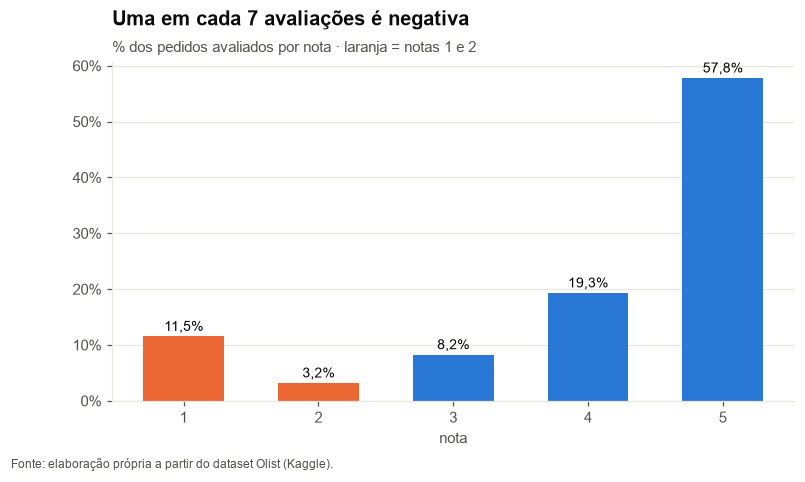

In [32]:
dist = base["review_score"].value_counts().sort_index().rename_axis("nota").rename("pedidos").reset_index()
dist["nota"] = dist["nota"].astype(int)
dist["pct"] = dist["pedidos"] / dist["pedidos"].sum()
book.add(id="I08", nome="% de avaliações negativas (nota 1–2)", definicao="Parte dos pedidos avaliados com nota 1 ou 2; a aba traz a distribuição das 5 notas.",
         formula="Pedidos com nota 1 ou 2 ÷ pedidos avaliados.", tabelas="order_reviews, orders", regras="R3, R5",
         valor=base["review_score"].isin([1, 2]).sum() / base["review_score"].notna().sum(), unidade="%",
         codigo='base.review_score.isin([1, 2]).sum() / base.review_score.notna().sum()',
         excel={"%": "(COUNTIF({base:review_score},1)+COUNTIF({base:review_score},2))/COUNT({base:review_score})"},
         tabela=dist, excel_linhas={"pedidos": "COUNTIF({base:review_score},{cell:nota})",
                                    "pct": "{cell:pedidos}/COUNT({base:review_score})"})

fig, ax = plt.subplots(figsize=(8, 4))
cores = [viz.SERIES[1] if n <= 2 else viz.SERIES[0] for n in dist["nota"]]
ax.bar(dist["nota"].astype(str), dist["pct"], color=cores, width=0.6)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.grid(axis="x", visible=False)
for x, v in enumerate(dist["pct"]):
    ax.text(x, v + 0.01, fmt_pct(v), ha="center", fontsize=9)
ax.set_xlabel("nota")
viz.titles(ax, f"Uma em cada {round(1 / book.items[-1].valor)} avaliações é negativa",
           "% dos pedidos avaliados por nota · laranja = notas 1 e 2")
viz.save(fig, "g08_distribuicao_notas")
plt.show()

### I09 · Nota no prazo × nota com atraso
**Definição:** quanto a nota média cai quando o pedido atrasa. · **Fórmula:** nota média dos entregues no prazo − nota média dos entregues com atraso. · **Origem:** orders, order_reviews · **Regras:** R3, R4, R6

A diferença mostra **associação**, não causa: outros fatores podem andar junto com o atraso. O OLIST-3 aprofunda.

I09 · Queda de nota com atraso: 2,02 pontos


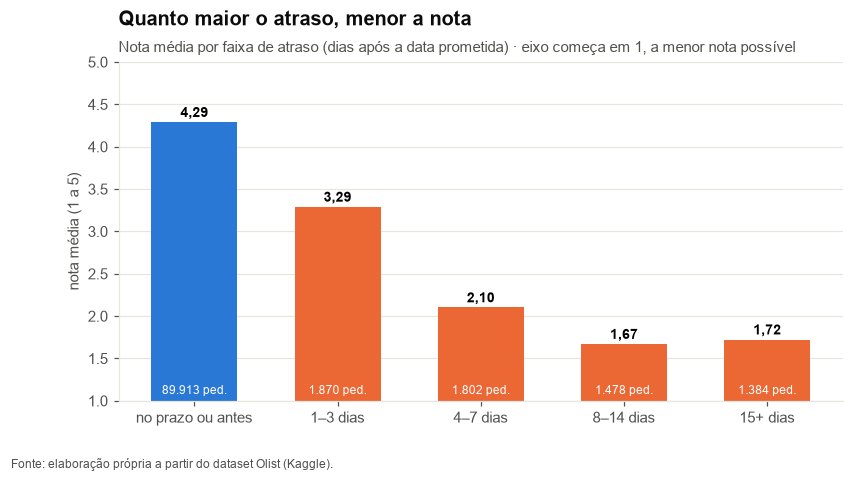

In [33]:
nota_prazo = ent.loc[ent["atrasado"] == 0, "review_score"].mean()
nota_atraso = ent.loc[ent["atrasado"] == 1, "review_score"].mean()
faixas = pd.cut(ent["atraso_dias"], [-np.inf, 0, 3, 7, 14, np.inf],
                labels=["no prazo ou antes", "1–3 dias", "4–7 dias", "8–14 dias", "15+ dias"])
tab_faixa = (ent.groupby(faixas, observed=True)
                .agg(pedidos=("order_id", "count"), nota_media=("review_score", "mean"))
                .rename_axis("faixa_de_atraso").reset_index())
tab_faixa["faixa_de_atraso"] = tab_faixa["faixa_de_atraso"].astype(str)
book.add(id="I09", nome="Queda de nota com atraso", definicao="Diferença entre a nota média dos pedidos entregues no prazo e a dos entregues com atraso.",
         formula="Nota média (entregues no prazo) − nota média (entregues com atraso).", tabelas="orders, order_reviews", regras="R3, R4, R6",
         valor=nota_prazo - nota_atraso, unidade="pontos", esperados=[nota_prazo - nota_atraso, nota_prazo, nota_atraso],
         codigo='ent[ent.atrasado == 0].review_score.mean() - ent[ent.atrasado == 1].review_score.mean()',
         excel={"diferença": "AVERAGEIFS({base:review_score},{base:atrasado},0)-AVERAGEIFS({base:review_score},{base:atrasado},1)",
                "nota no prazo": "AVERAGEIFS({base:review_score},{base:atrasado},0)",
                "nota com atraso": "AVERAGEIFS({base:review_score},{base:atrasado},1)"},
         tabela=tab_faixa)

fig, ax = plt.subplots(figsize=(8.5, 4))
cores = [viz.SERIES[0]] + [viz.SERIES[1]] * (len(tab_faixa) - 1)
ax.bar(tab_faixa["faixa_de_atraso"], tab_faixa["nota_media"], color=cores, width=0.6)
ax.set_ylim(1, 5)
ax.grid(axis="x", visible=False)
for x, (v, n) in enumerate(zip(tab_faixa["nota_media"], tab_faixa["pedidos"])):
    ax.text(x, v + 0.06, f"{v:.2f}".replace(".", ","), ha="center", fontsize=9, fontweight="bold")
    ax.text(x, 1.08, f"{fmt_int(n)} ped.", ha="center", fontsize=8, color="white")
ax.set_ylabel("nota média (1 a 5)")
viz.titles(ax, "Quanto maior o atraso, menor a nota",
           "Nota média por faixa de atraso (dias após a data prometida) · eixo começa em 1, a menor nota possível")
viz.save(fig, "g09_nota_por_faixa_de_atraso")
plt.show()

### I10 · % de avaliações com comentário
**Definição:** parte dos pedidos avaliados em que o cliente escreveu um comentário. · **Fórmula:** avaliações com texto ÷ pedidos avaliados. · **Origem:** order_reviews · **Regras:** R3, R5

Esse é o volume de texto disponível para um agente de IA ler e classificar.

In [34]:
book.add(id="I10", nome="% de avaliações com comentário", definicao="Parte dos pedidos avaliados em que o cliente escreveu um comentário.",
         formula="Avaliações com comentário preenchido ÷ pedidos avaliados.", tabelas="order_reviews", regras="R3, R5",
         valor=base["tem_comentario"].mean(), unidade="%", codigo='base["tem_comentario"].mean()',
         excel={"%": "AVERAGE({base:tem_comentario})"})

I10 · % de avaliações com comentário: 41,3%


Indicator(id='I10', nome='% de avaliações com comentário', definicao='Parte dos pedidos avaliados em que o cliente escreveu um comentário.', formula='Avaliações com comentário preenchido ÷ pedidos avaliados.', tabelas='order_reviews', regras='R3, R5', valor=np.float64(0.41295997892027203), unidade='%', codigo='base["tem_comentario"].mean()', tabela=None, excel={'%': 'AVERAGE({base:tem_comentario})'}, excel_linhas={}, esperados=None)

### I11 · % de pedidos cancelados ou indisponíveis
**Definição:** parte dos pedidos que não se concretizaram por cancelamento ou falta do produto. · **Fórmula:** pedidos com status `canceled` ou `unavailable` ÷ pedidos totais. · **Origem:** orders · **Regras:** R1

In [35]:
tab_status = base["order_status"].value_counts().rename_axis("status").rename("pedidos").reset_index()
book.add(id="I11", nome="% de pedidos cancelados ou indisponíveis", definicao="Parte dos pedidos que não se concretizaram por cancelamento ou indisponibilidade.",
         formula="Pedidos com status canceled ou unavailable ÷ pedidos totais.", tabelas="orders", regras="R1",
         valor=base["cancelado_indisp"].mean(), unidade="%", codigo='base["cancelado_indisp"].mean()',
         excel={"%": "AVERAGE({base:cancelado_indisp})"},
         tabela=tab_status, excel_linhas={"pedidos": "COUNTIF({base:order_status},{cell:status})"})

I11 · % de pedidos cancelados ou indisponíveis: 1,2%


Indicator(id='I11', nome='% de pedidos cancelados ou indisponíveis', definicao='Parte dos pedidos que não se concretizaram por cancelamento ou indisponibilidade.', formula='Pedidos com status canceled ou unavailable ÷ pedidos totais.', tabelas='orders', regras='R1', valor=np.float64(0.012409368369183738), unidade='%', codigo='base["cancelado_indisp"].mean()', tabela=        status  pedidos
0    delivered    96478
1      shipped     1107
2     canceled      625
3  unavailable      609
4     invoiced      314
5   processing      301
6      created        5
7     approved        2, excel={'%': 'AVERAGE({base:cancelado_indisp})'}, excel_linhas={'pedidos': 'COUNTIF({base:order_status},{cell:status})'}, esperados=None)

### I12 · Taxa de recompra
**Definição:** parte dos clientes que fizeram mais de um pedido no período. · **Fórmula:** clientes (`customer_unique_id`) com 2 ou mais pedidos ÷ total de clientes. · **Origem:** orders, customers · **Regras:** R1, R2

**Cautela:** recompra baixa não é o mesmo que churn. O período é curto e muitas compras são pontuais por natureza.

In [36]:
tab_cli = base.groupby("customer_unique_id").size().rename("pedidos").reset_index().sort_values("pedidos", ascending=False, ignore_index=True)
book.add(id="I12", nome="Taxa de recompra", definicao="Parte dos clientes (pessoas) que fizeram dois ou mais pedidos no período.",
         formula="Clientes com 2 ou mais pedidos ÷ total de clientes (customer_unique_id).", tabelas="orders, customers", regras="R1, R2",
         valor=(tab_cli["pedidos"] >= 2).mean(), unidade="%",
         codigo='(base.groupby("customer_unique_id").size() >= 2).mean()',
         excel={"%": 'COUNTIF({tab:pedidos},">=2")/COUNTA({tab:customer_unique_id})'},
         tabela=tab_cli)

I12 · Taxa de recompra: 3,1%


Indicator(id='I12', nome='Taxa de recompra', definicao='Parte dos clientes (pessoas) que fizeram dois ou mais pedidos no período.', formula='Clientes com 2 ou mais pedidos ÷ total de clientes (customer_unique_id).', tabelas='orders, customers', regras='R1, R2', valor=np.float64(0.031187562437562436), unidade='%', codigo='(base.groupby("customer_unique_id").size() >= 2).mean()', tabela=                     customer_unique_id  pedidos
0      8d50f5eadf50201ccdcedfb9e2ac8455       17
1      3e43e6105506432c953e165fb2acf44c        9
2      1b6c7548a2a1f9037c1fd3ddfed95f33        7
3      6469f99c1f9dfae7733b25662e7f1782        7
4      ca77025e7201e3b30c44b472ff346268        7
...                                 ...      ...
96091  ffeefd086fc667aaf6595c8fe3d22d54        1
96092  ffef0ffa736c7b3d9af741611089729b        1
96093  fff1afc79f6b5db1e235a4a6c30ceda7        1
96094  fff1bdd5c5e37ca79dd74deeb91aa5b6        1
96095  fff22793223fe80c97a8fd02ac5c6295        1

[96096 rows x 2 columns

### I13 · Ticket médio
**Definição:** valor médio pago por pedido. · **Fórmula:** soma dos pagamentos de cada pedido e média entre os pedidos. · **Origem:** payments · **Regras:** R1, R8

In [37]:
book.add(id="I13", nome="Ticket médio", definicao="Valor médio pago por pedido (inclui frete e eventuais juros).",
         formula="Média, entre os pedidos, da soma dos pagamentos de cada pedido.", tabelas="payments, orders", regras="R1, R8",
         valor=base["valor_pago"].mean(), unidade="R$", codigo='base["valor_pago"].mean()',
         excel={"R$": "AVERAGE({base:valor_pago})"})

I13 · Ticket médio: R$ 160,99


Indicator(id='I13', nome='Ticket médio', definicao='Valor médio pago por pedido (inclui frete e eventuais juros).', formula='Média, entre os pedidos, da soma dos pagamentos de cada pedido.', tabelas='payments, orders', regras='R1, R8', valor=np.float64(160.9902666934835), unidade='R$', codigo='base["valor_pago"].mean()', tabela=None, excel={'R$': 'AVERAGE({base:valor_pago})'}, excel_linhas={}, esperados=None)

### I14 · Peso do frete no valor
**Definição:** quanto do valor dos itens vendidos é frete. · **Fórmula:** soma do frete ÷ (soma dos preços + soma do frete). · **Origem:** order_items · **Regras:** R1, R8

In [38]:
book.add(id="I14", nome="Peso do frete no valor", definicao="Parte do valor total dos itens (preço + frete) que corresponde ao frete.",
         formula="Soma do frete ÷ (soma dos preços + soma do frete).", tabelas="order_items", regras="R1, R8",
         valor=base["valor_frete"].sum() / (base["valor_itens"].sum() + base["valor_frete"].sum()), unidade="%",
         codigo='base.valor_frete.sum() / (base.valor_itens.sum() + base.valor_frete.sum())',
         excel={"%": "SUM({base:valor_frete})/(SUM({base:valor_itens})+SUM({base:valor_frete}))"})

I14 · Peso do frete no valor: 14,2%


Indicator(id='I14', nome='Peso do frete no valor', definicao='Parte do valor total dos itens (preço + frete) que corresponde ao frete.', formula='Soma do frete ÷ (soma dos preços + soma do frete).', tabelas='order_items', regras='R1, R8', valor=np.float64(0.1421341226862315), unidade='%', codigo='base.valor_frete.sum() / (base.valor_itens.sum() + base.valor_frete.sum())', tabela=None, excel={'%': 'SUM({base:valor_frete})/(SUM({base:valor_itens})+SUM({base:valor_frete}))'}, excel_linhas={}, esperados=None)

### I15 · Taxa de atraso por estado (UF)
**Definição:** taxa de atraso (I05) calculada para cada estado do cliente. O valor do indicador é a **maior taxa** entre os estados com pelo menos 500 entregas. · **Fórmula:** por UF, atrasados ÷ entregues válidos. · **Origem:** orders, customers · **Regras:** R2, R4, R6

I15 · Maior taxa de atraso por UF: 17,4%


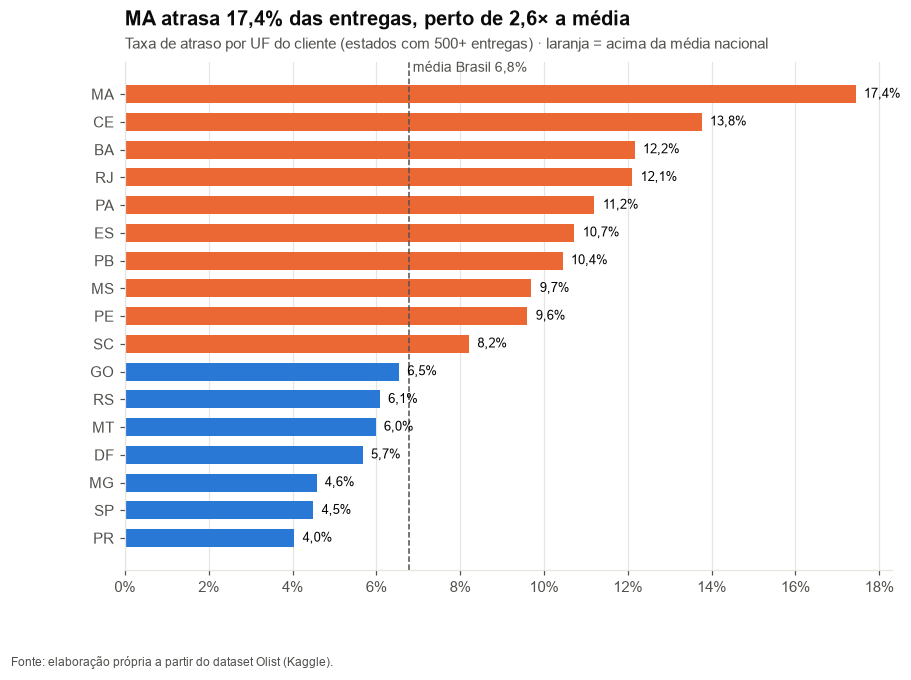

In [39]:
tab_uf = (ent.groupby("customer_state").agg(entregues=("order_id", "count"), atrasados=("atrasado", "sum"))
             .reset_index().rename(columns={"customer_state": "uf"}))
tab_uf["atrasados"] = tab_uf["atrasados"].astype(int)
tab_uf["taxa_atraso"] = tab_uf["atrasados"] / tab_uf["entregues"]
tab_uf = tab_uf.sort_values("taxa_atraso", ascending=False, ignore_index=True)
grandes = tab_uf[tab_uf["entregues"] >= 500]
pior = grandes.iloc[0]
book.add(id="I15", nome="Maior taxa de atraso por UF", definicao=f"Taxa de atraso por estado do cliente; o valor é a maior entre os estados com 500+ entregas ({pior['uf']}).",
         formula="Por UF: pedidos atrasados ÷ pedidos entregues válidos; valor = maior taxa entre UFs com 500+ entregas.",
         tabelas="orders, customers", regras="R2, R4, R6", valor=pior["taxa_atraso"], unidade="%",
         codigo='ent.groupby("customer_state").atrasado.mean()',
         excel={"%": 'MAXIFS({tab:taxa_atraso},{tab:entregues},">=500")'},
         tabela=tab_uf,
         excel_linhas={"entregues": "COUNTIFS({base:customer_state},{cell:uf},{base:entregue_valido},1)",
                       "atrasados": "COUNTIFS({base:customer_state},{cell:uf},{base:atrasado},1)",
                       "taxa_atraso": "{cell:atrasados}/{cell:entregues}"})

taxa_br = book.items[4].valor  # I05
g = grandes.sort_values("taxa_atraso")
fig, ax = plt.subplots(figsize=(9, 6))
cores = [viz.SERIES[1] if v > taxa_br else viz.SERIES[0] for v in g["taxa_atraso"]]
ax.barh(g["uf"], g["taxa_atraso"], color=cores, height=0.65)
ax.axvline(taxa_br, color=viz.TEXT_2, ls="--", lw=1)
ax.xaxis.set_major_locator(MultipleLocator(0.02))
ax.text(taxa_br, len(g) - 0.3, f" média Brasil {fmt_pct(taxa_br)}", color=viz.TEXT_2, fontsize=9, va="bottom")
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.grid(axis="y", visible=False)
for y, v in enumerate(g["taxa_atraso"]):
    ax.text(v + 0.002, y, fmt_pct(v), va="center", fontsize=8.5)
viz.titles(ax, f"{pior['uf']} atrasa {fmt_pct(pior['taxa_atraso'])} das entregas, perto de {pior['taxa_atraso'] / taxa_br:.1f}× a média".replace(".", ","),
           "Taxa de atraso por UF do cliente (estados com 500+ entregas) · laranja = acima da média nacional")
viz.save(fig, "g10_atraso_por_uf")
plt.show()

In [40]:
indicadores = book.to_frame()
indicadores

,id,nome,definicao,formula,tabelas,regras,valor
0,I01,Pedidos totais,Quantidade de pedidos distintos no dataset.,Contagem de order_id distintos da tabela orders.,orders,R1,99.441 pedidos
1,I02,Período coberto,Primeira e última data de compra registradas.,Menor e maior data de compra (order_purchase_t...,orders,—,04/09/2016 a 17/10/2018
2,I03,% de pedidos entregues válidos,Parte dos pedidos entregues com datas confiáve...,Pedidos entregues válidos ÷ pedidos totais.,orders,"R1, R4, R6","97,0%"
3,I04,Prazo médio de entrega,Tempo médio entre a compra e a entrega ao clie...,"Média de (data de entrega − data de compra), e...",orders,"R4, R6","12,56 dias"
4,I05,Taxa de atraso,Parte dos pedidos entregues que chegaram depoi...,Pedidos entregues após a data prometida ÷ pedi...,orders,"R4, R6","6,8%"
5,I06,Atraso médio dos atrasados,"Dias além da data prometida, em média, quando ...","Média de (data de entrega − data prometida), e...",orders,"R4, R6","10,62 dias"
6,I07,Nota média de avaliação,Média das notas de 1 a 5 dadas pelos clientes.,"Média de review_score, com uma avaliação por p...","order_reviews, orders","R3, R5","4,09 (1 a 5)"
7,I08,% de avaliações negativas (nota 1–2),Parte dos pedidos avaliados com nota 1 ou 2; a...,Pedidos com nota 1 ou 2 ÷ pedidos avaliados.,"order_reviews, orders","R3, R5","14,7%"
8,I09,Queda de nota com atraso,Diferença entre a nota média dos pedidos entre...,Nota média (entregues no prazo) − nota média (...,"orders, order_reviews","R3, R4, R6","2,02 pontos"
9,I10,% de avaliações com comentário,Parte dos pedidos avaliados em que o cliente e...,Avaliações com comentário preenchido ÷ pedidos...,order_reviews,"R3, R5","41,3%"


## Etapa 8 · Exportação
- **Excel** (`reports/indicadores_olist.xlsx`): uma aba por indicador. Cada aba tem a fórmula viva do Excel, o valor calculado no Python e uma coluna *confere*, além das abas Indicadores, Regras, Inventario e base_pedidos.
- **JSON** (`reports/indicadores.json`): os mesmos números, lidos pelo gerador do Word e usados no Confluence. Assim nenhum número é digitado à mão.
- **Figuras** (`reports/figures/`): os PNGs dos gráficos acima.

In [41]:
meta = {"pedidos": len(base), "inicio": ini, "fim": fim_, "meses_de_borda": borda,
        "clientes": int(base["customer_unique_id"].nunique()), "entregues_validos": int(base["entregue_valido"].sum()),
        "tabelas": len(t), "integridade": integ.to_dict("records"), "granularidade": gran.to_dict("records")}
print("Excel:", to_excel(book, regras, inventario, base))
print("JSON: ", to_json(book, regras, inventario, meta))
print("Figuras:", sorted(p.name for p in config.FIGURES.glob("*.png")))

Excel: C:\Users\igor_\OneDrive\Área de Trabalho\Case FIAP\reports\indicadores_olist.xlsx
JSON:  C:\Users\igor_\OneDrive\Área de Trabalho\Case FIAP\reports\indicadores.json
Figuras: ['g01_registros_por_tabela.png', 'g02_linhas_por_entidade.png', 'g03_mapa_de_chaves.png', 'g04_integridade_referencial.png', 'g05_nulos_por_coluna.png', 'g06_pedidos_por_mes.png', 'g07_pedidos_por_status.png', 'g08_distribuicao_notas.png', 'g09_nota_por_faixa_de_atraso.png', 'g10_atraso_por_uf.png']


## Etapa 9 · Checklist dos critérios de aceite do OLIST-2
O checklist marca automaticamente o que o notebook comprova. O CA4 depende de um colega, Diogo ou Lorran. Ele abre o Excel e confere pelo menos 3 indicadores na coluna *confere*.

In [42]:
checklist = pd.DataFrame([
    ("CA1", "As 8 tabelas do enunciado inventariadas, com registros e granularidade",
     set(config.ENUNCIADO_TABLES) <= set(inventario["tabela"]), "Etapas 1–2 · aba Inventario · g01–g03"),
    ("CA2", "≥ 6 regras de qualidade em linguagem simples", len(regras) >= 6, f"Etapa 5 · {len(regras)} regras · aba Regras"),
    ("CA3", "≥ 10 indicadores com definição, fórmula e tabela de origem",
     len(indicadores) >= 10 and indicadores[["definicao", "formula", "tabelas"]].ne("").all().all(), f"Etapa 7 · {len(indicadores)} indicadores · aba Indicadores"),
    ("CA4", "Um colega reproduziu ≥ 3 indicadores e os valores bateram", None, "Pendente: Diogo ou Lorran confere no Excel"),
    ("CA5", "Período coberto e nº de pedidos declarados", True, f"I01 = {book.items[0].texto()} · I02 = {book.items[1].texto()}"),
    ("CA6", "Nenhum número copiado do relatório de referência", True, "Todos os números saem deste notebook a partir dos CSVs"),
], columns=["CA", "critério", "atendido", "evidência"])
checklist["atendido"] = checklist["atendido"].map(lambda v: "pendente" if v is None else ("sim" if v else "NÃO"))
checklist

,CA,critério,atendido,evidência
0,CA1,"As 8 tabelas do enunciado inventariadas, com r...",sim,Etapas 1–2 · aba Inventario · g01–g03
1,CA2,≥ 6 regras de qualidade em linguagem simples,sim,Etapa 5 · 8 regras · aba Regras
2,CA3,"≥ 10 indicadores com definição, fórmula e tabe...",sim,Etapa 7 · 15 indicadores · aba Indicadores
3,CA4,Um colega reproduziu ≥ 3 indicadores e os valo...,pendente,Pendente: Diogo ou Lorran confere no Excel
4,CA5,Período coberto e nº de pedidos declarados,sim,I01 = 99.441 pedidos · I02 = 04/09/2016 a 17/1...
5,CA6,Nenhum número copiado do relatório de referência,sim,Todos os números saem deste notebook a partir ...
